In [ ]:
import os
import glob
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import precision_recall_fscore_support

warnings.filterwarnings("ignore")
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120

print("Libraries loaded successfully!")


Libraries loaded successfully!


In [ ]:
def load_user_geolife_trajectories(user_id, base_dir='task12/data', max_files=40, subsample_step=8):
    if not os.path.exists(base_dir):
        base_dir = os.path.join('data')
        
    user_traj_dir = os.path.join(base_dir, user_id, 'Trajectory')
    plt_files = sorted(glob.glob(os.path.join(user_traj_dir, '*.plt')))
    
    if len(plt_files) == 0:
        raise FileNotFoundError(f"No .plt files found in {user_traj_dir}")
        
    files_to_load = plt_files[:max_files]
    traj_list = []
    
    for f in files_to_load:
        try:
            df = pd.read_csv(f, skiprows=6, header=None,
                             names=['lat', 'lon', 'unused', 'alt', 'days', 'date', 'time'])
            df = df[(df['lat'] >= -90.0) & (df['lat'] <= 90.0)]
            df = df[(df['lon'] >= -180.0) & (df['lon'] <= 180.0)]
            df = df[df['alt'] != -777]
            
            df['datetime'] = pd.to_datetime(df['date'] + ' ' + df['time'])
            df['user_id'] = user_id
            
            df_sampled = df.iloc[::subsample_step][['lat', 'lon', 'alt', 'datetime', 'user_id']]
            traj_list.append(df_sampled)
        except Exception as e:
            continue
            
    if not traj_list:
        raise ValueError(f"No valid trajectory points loaded for user {user_id}")
        
    user_df = pd.concat(traj_list, ignore_index=True)
    user_df = user_df.sort_values('datetime').drop_duplicates(subset=['datetime']).reset_index(drop=True)
    return user_df

selected_users = ['000', '001', '002']
user_data = {}
summary_list = []

for u in selected_users:
    df_u = load_user_geolife_trajectories(u, base_dir='task12/data', max_files=35, subsample_step=10)
    user_data[u] = df_u
    
    n_total = len(df_u)
    n_train = int(0.8 * n_total)
    df_train = df_u.iloc[:n_train].copy().reset_index(drop=True)
    df_test = df_u.iloc[n_train:].copy().reset_index(drop=True)
    
    user_data[f"{u}_train"] = df_train
    user_data[f"{u}_test"] = df_test
    
    summary_list.append({
        "User ID": u,
        "Total Points": n_total,
        "Train Points (80%)": len(df_train),
        "Test Points (20%)": len(df_test),
        "Start Time": str(df_u['datetime'].min()),
        "End Time": str(df_u['datetime'].max()),
        "Lat Range": f"[{df_u['lat'].min():.3f}, {df_u['lat'].max():.3f}]",
        "Lon Range": f"[{df_u['lon'].min():.3f}, {df_u['lon'].max():.3f}]"
    })

df_summary = pd.DataFrame(summary_list)
print("Task 1: Preprocessed GeoLife GPS Trajectory Summary Table:")
display(df_summary)


,User ID,Total Points,Train Points (80%),Test Points (20%),Start Time,End Time,Lat Range,Lon Range
0,000,1221,976,245,2008-10-23 02:53:04,2008-12-03 15:53:50,"[39.887, 40.018]","[116.295, 116.394]"
1,001,6111,4888,1223,2008-10-23 05:53:05,2008-11-15 10:12:20,"[39.901, 40.076]","[116.145, 116.422]"
2,002,8135,6508,1627,2008-10-23 12:45:23,2008-11-17 13:59:36,"[39.879, 40.004]","[116.101, 116.391]"


Task 1: Preprocessed GeoLife GPS Trajectory Summary Table:


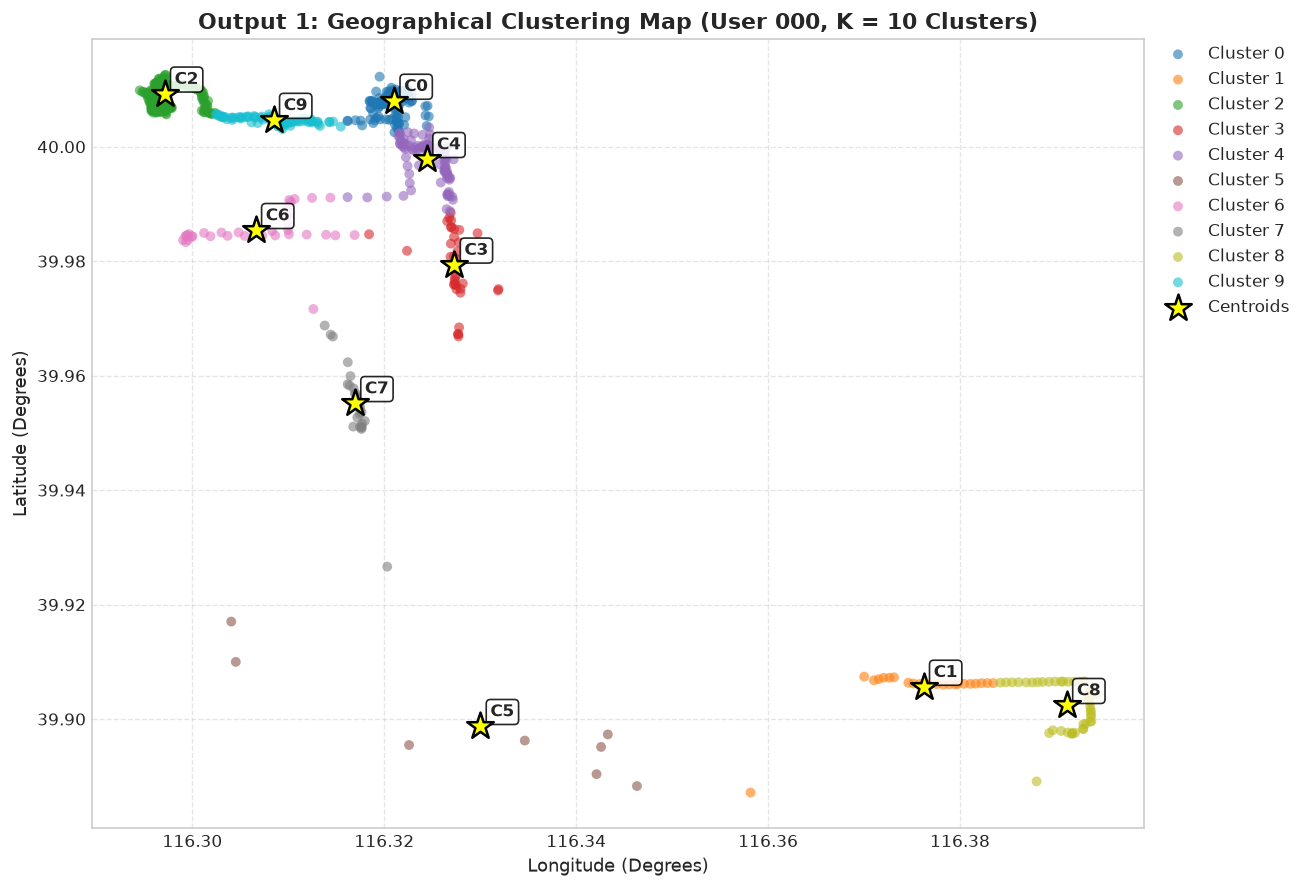

K-Means fitted with K = 10 clusters.
Training sequence length: 976 discrete location tokens.
Testing sequence length: 245 discrete location tokens.


In [ ]:
primary_user = '000'
train_coords = user_data[f"{primary_user}_train"][['lat', 'lon']].values
test_coords = user_data[f"{primary_user}_test"][['lat', 'lon']].values

K_default = 10
kmeans_model = KMeans(n_clusters=K_default, random_state=42, n_init=10).fit(train_coords)

train_clusters = kmeans_model.predict(train_coords)
test_clusters = kmeans_model.predict(test_coords)

user_data[f"{primary_user}_train"]['cluster'] = train_clusters
user_data[f"{primary_user}_test"]['cluster'] = test_clusters

cluster_centroids = kmeans_model.cluster_centers_  # Shape: (K, 2) [lat, lon]

print(f"K-Means fitted with K = {K_default} clusters.")
print(f"Training sequence length: {len(train_clusters)} discrete location tokens.")
print(f"Testing sequence length: {len(test_clusters)} discrete location tokens.")

fig, ax = plt.subplots(figsize=(11, 7.5))
palette = sns.color_palette("tab10", K_default)

for k in range(K_default):
    pts = train_coords[train_clusters == k]
    if len(pts) > 0:
        ax.scatter(pts[:, 1], pts[:, 0], color=palette[k], alpha=0.6, s=35, label=f"Cluster {k}", edgecolors='none')

ax.scatter(cluster_centroids[:, 1], cluster_centroids[:, 0], c='yellow', marker='*', s=280, 
           edgecolors='black', linewidth=1.5, label='Centroids', zorder=5)

for k, (clat, clon) in enumerate(cluster_centroids):
    ax.annotate(f"C{k}", (clon, clat), fontsize=10, fontweight='bold',
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="black", alpha=0.85),
                xytext=(6, 6), textcoords="offset points")

ax.set_title(f"Output 1: Geographical Clustering Map (User {primary_user}, K = {K_default} Clusters)", fontsize=13, fontweight='bold')
ax.set_xlabel("Longitude (Degrees)", fontsize=11)
ax.set_ylabel("Latitude (Degrees)", fontsize=11)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0.)
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


In [ ]:
class LocationHMM:

    def __init__(self, n_states=3, n_symbols=10, random_state=42):
        self.M = n_states   
        self.K = n_symbols    
        self.random_state = random_state
        
        rng = np.random.RandomState(random_state)
        self.pi = rng.dirichlet(np.ones(self.M) * 3.0)
        self.A = rng.dirichlet(np.ones(self.M) * 3.0, size=self.M)
        self.B = rng.dirichlet(np.ones(self.K) * 2.0, size=self.M)
        self.log_likelihood_history = []
        self.train_time = 0.0

    def fit(self, sequences, max_iter=25, tol=1e-4, smooth=1e-3):
        start_time = time.time()
        if not isinstance(sequences[0], (list, np.ndarray, pd.Series)):
            sequences = [sequences]
            
        self.log_likelihood_history = []
        
        for iteration in range(max_iter):
            total_ll = 0.0
            pi_acc = np.zeros(self.M)
            A_num = np.zeros((self.M, self.M))
            A_den = np.zeros(self.M)
            B_num = np.zeros((self.M, self.K))
            B_den = np.zeros(self.M)

            for seq in sequences:
                seq = np.asarray(seq, dtype=int)
                T = len(seq)
                if T < 2:
                    continue
                    
                alpha = np.zeros((T, self.M))
                c = np.zeros(T)
                alpha[0] = self.pi * self.B[:, seq[0]]
                c[0] = np.sum(alpha[0]) + 1e-12
                alpha[0] /= c[0]
                
                for t in range(1, T):
                    alpha[t] = (alpha[t-1] @ self.A) * self.B[:, seq[t]]
                    c[t] = np.sum(alpha[t]) + 1e-12
                    alpha[t] /= c[t]
                    
                total_ll += np.sum(np.log(np.maximum(c, 1e-12)))

                beta = np.zeros((T, self.M))
                beta[-1] = 1.0 / c[-1]
                for t in range(T-2, -1, -1):
                    beta[t] = (self.A @ (self.B[:, seq[t+1]] * beta[t+1])) / c[t]

                gamma = alpha * beta
                gamma /= np.sum(gamma, axis=1, keepdims=True) + 1e-12

                for t in range(T-1):
                    xi_t = (alpha[t, :, None] * self.A * self.B[:, seq[t+1]] * beta[t+1, None, :])
                    xi_t /= np.sum(xi_t) + 1e-12
                    A_num += xi_t
                    A_den += gamma[t]

                pi_acc += gamma[0]
                for k in range(self.K):
                    mask = (seq == k)
                    if np.any(mask):
                        B_num[:, k] += np.sum(gamma[mask], axis=0)
                B_den += np.sum(gamma, axis=0)

            self.pi = (pi_acc + smooth) / (np.sum(pi_acc) + smooth * self.M)
            self.A = (A_num + smooth) / (A_den[:, None] + smooth * self.M)
            self.B = (B_num + smooth) / (B_den[:, None] + smooth * self.K)
            
            self.log_likelihood_history.append(total_ll)
            if iteration > 0 and abs(self.log_likelihood_history[-1] - self.log_likelihood_history[-2]) < tol:
                break
                
        self.train_time = time.time() - start_time
        return self

    def forward_state_distribution(self, obs_seq):
        obs_seq = np.asarray(obs_seq, dtype=int)
        T = len(obs_seq)
        alpha = np.zeros((T, self.M))
        
        alpha[0] = self.pi * self.B[:, obs_seq[0]]
        alpha[0] /= np.sum(alpha[0]) + 1e-12
        for t in range(1, T):
            alpha[t] = (alpha[t-1] @ self.A) * self.B[:, obs_seq[t]]
            alpha[t] /= np.sum(alpha[t]) + 1e-12
        return alpha[-1] 

    def predict_next_location(self, obs_seq):
        curr_state_dist = self.forward_state_distribution(obs_seq)
        next_state_dist = curr_state_dist @ self.A
        next_obs_probs = next_state_dist @ self.B
        next_obs_probs /= np.sum(next_obs_probs)
        
        top1_cluster = int(np.argmax(next_obs_probs))
        top3_clusters = list(np.argsort(next_obs_probs)[-3:][::-1])
        return next_obs_probs, top1_cluster, top3_clusters

    def viterbi(self, obs_seq):
        obs_seq = np.asarray(obs_seq, dtype=int)
        T = len(obs_seq)
        delta = np.zeros((T, self.M))
        psi = np.zeros((T, self.M), dtype=int)

        delta[0] = np.log(self.pi + 1e-12) + np.log(self.B[:, obs_seq[0]] + 1e-12)
        for t in range(1, T):
            for j in range(self.M):
                scores = delta[t-1] + np.log(self.A[:, j] + 1e-12)
                psi[t, j] = np.argmax(scores)
                delta[t, j] = scores[psi[t, j]] + np.log(self.B[j, obs_seq[t]] + 1e-12)

        states = np.zeros(T, dtype=int)
        states[-1] = np.argmax(delta[-1])
        for t in range(T-2, -1, -1):
            states[t] = psi[t+1, states[t+1]]
        return states

print("LocationHMM class defined successfully!")


LocationHMM class defined successfully!


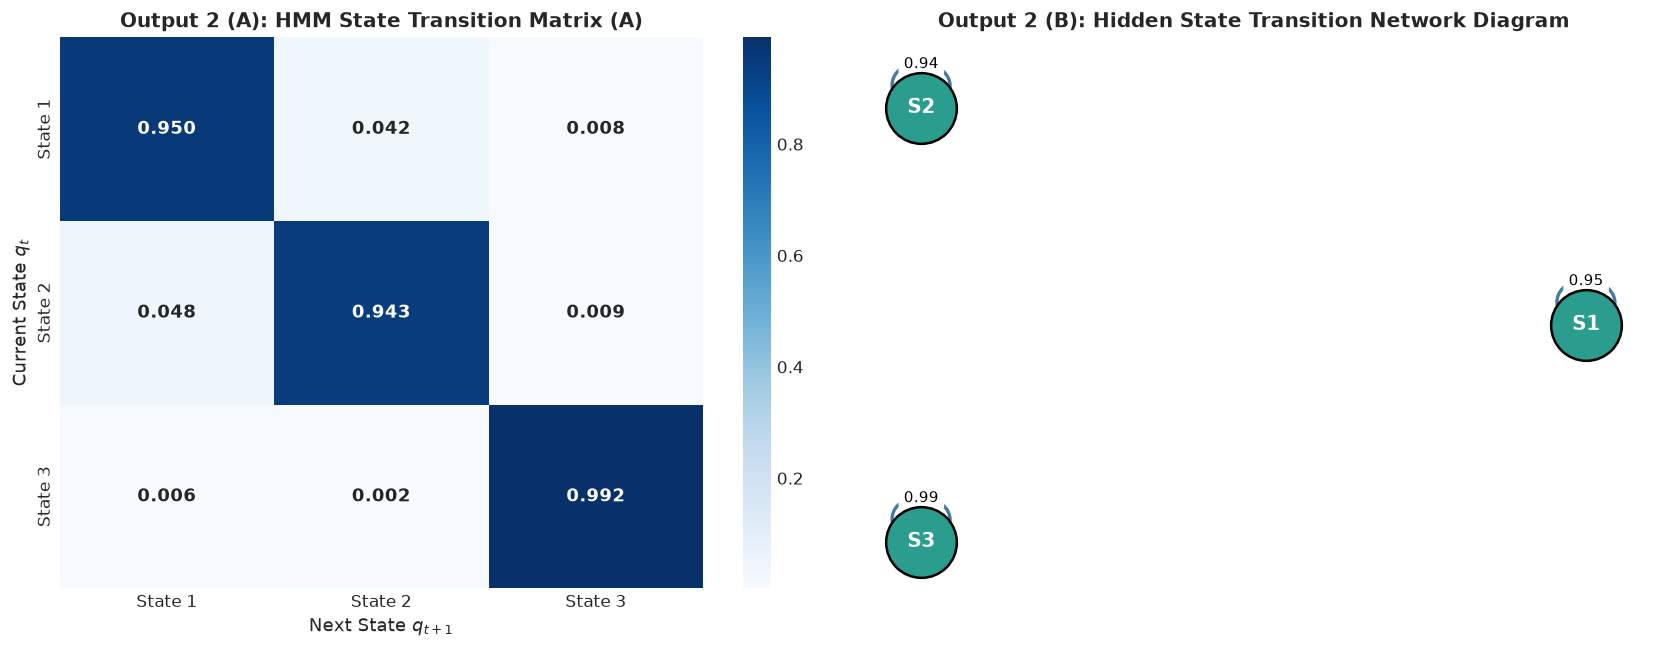

HMM Training Complete in 0.177s across 14 iterations.

Learned Initial State Probabilities (pi): [0.001 0.998 0.001]


In [ ]:

M_default = 3
hmm_baseline = LocationHMM(n_states=M_default, n_symbols=K_default, random_state=42)
hmm_baseline.fit(train_clusters, max_iter=30)

print(f"HMM Training Complete in {hmm_baseline.train_time:.3f}s across {len(hmm_baseline.log_likelihood_history)} iterations.")
print("\nLearned Initial State Probabilities (pi):", np.round(hmm_baseline.pi, 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(hmm_baseline.A, annot=True, fmt=".3f", cmap="Blues", cbar=True,
            xticklabels=[f"State {i+1}" for i in range(M_default)],
            yticklabels=[f"State {i+1}" for i in range(M_default)],
            ax=axes[0], annot_kws={"size": 11, "weight": "bold"})
axes[0].set_title("Output 2 (A): HMM State Transition Matrix (A)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Next State $q_{t+1}$", fontsize=11)
axes[0].set_ylabel("Current State $q_t$", fontsize=11)

import networkx as nx

G = nx.DiGraph()
for i in range(M_default):
    G.add_node(f"S{i+1}")

for i in range(M_default):
    for j in range(M_default):
        prob = hmm_baseline.A[i, j]
        if prob > 0.05:
            G.add_edge(f"S{i+1}", f"S{j+1}", weight=prob)

pos = nx.circular_layout(G)
nx.draw_networkx_nodes(G, pos, node_color="#2a9d8f", node_size=1800, ax=axes[1], edgecolors="k", linewidths=1.5)
nx.draw_networkx_labels(G, pos, font_color="white", font_size=12, font_weight="bold", ax=axes[1])
nx.draw_networkx_edges(G, pos, arrowstyle="->", arrowsize=20, edge_color="#457b9d", 
                       connectionstyle="arc3,rad=0.18", width=2.0, ax=axes[1])

edge_labels = {(u, v): f"{d['weight']:.2f}" for u, v, d in G.edges(data=True)}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=9, ax=axes[1], label_pos=0.3)

axes[1].set_title("Output 2 (B): Hidden State Transition Network Diagram", fontsize=12, fontweight='bold')
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [ ]:
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371.0
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlam = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2.0)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(dlam / 2.0)**2
    return 2.0 * R * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0)))


def evaluate_location_prediction(hmm_model, test_seq, test_coords, centroids, history_len=5):

    start_eval = time.time()
    n_test = len(test_seq)
    
    top1_correct = 0
    top3_correct = 0
    actual_labels = []
    predicted_labels = []
    haversine_errors = []
    pred_coords = []
    
    for t in range(history_len, n_test):
        window_obs = test_seq[max(0, t - history_len):t]
        actual_cluster = test_seq[t]
        actual_lat, actual_lon = test_coords[t]
        
        probs, top1, top3 = hmm_model.predict_next_location(window_obs)
        
        pred_lat, pred_lon = centroids[top1]
        dist_km = haversine_distance(actual_lat, actual_lon, pred_lat, pred_lon)
        
        if top1 == actual_cluster:
            top1_correct += 1
        if actual_cluster in top3:
            top3_correct += 1
            
        actual_labels.append(actual_cluster)
        predicted_labels.append(top1)
        haversine_errors.append(dist_km)
        pred_coords.append((pred_lat, pred_lon))
        
    eval_time = time.time() - start_eval
    n_preds = len(actual_labels)
    
    precision, recall, f1, _ = precision_recall_fscore_support(actual_labels, predicted_labels, average='macro', zero_division=0)
    
    return {
        "Top-1 Accuracy": top1_correct / n_preds,
        "Top-3 Accuracy": top3_correct / n_preds,
        "Precision (Macro)": precision,
        "Recall (Macro)": recall,
        "F1-Score (Macro)": f1,
        "Mean Haversine (km)": np.mean(haversine_errors),
        "Median Haversine (km)": np.median(haversine_errors),
        "Execution Time (s)": eval_time,
        "actual_labels": actual_labels,
        "predicted_labels": predicted_labels,
        "pred_coords": np.array(pred_coords),
        "actual_coords": test_coords[history_len:]
    }

baseline_eval = evaluate_location_prediction(hmm_baseline, test_clusters, test_coords, cluster_centroids, history_len=5)
viterbi_states = hmm_baseline.viterbi(test_clusters)

print("Baseline Performance Evaluation Metrics (User 000):")
print(f"  * Top-1 Accuracy:       {baseline_eval['Top-1 Accuracy'] * 100:.2f}%")
print(f"  * Top-3 Accuracy:       {baseline_eval['Top-3 Accuracy'] * 100:.2f}%")
print(f"  * Precision (Macro):    {baseline_eval['Precision (Macro)']:.4f}")
print(f"  * Recall (Macro):       {baseline_eval['Recall (Macro)']:.4f}")
print(f"  * F1-Score (Macro):     {baseline_eval['F1-Score (Macro)']:.4f}")
print(f"  * Mean Haversine Error: {baseline_eval['Mean Haversine (km)']:.3f} km ({baseline_eval['Mean Haversine (km)']*1000:.1f} meters)")
print(f"  * Median Error:         {baseline_eval['Median Haversine (km)']:.3f} km")
print(f"  * Inference Time:       {baseline_eval['Execution Time (s)']:.4f} s")
print(f"  * Viterbi decoded state distribution: {np.bincount(viterbi_states)}")


Baseline Performance Evaluation Metrics (User 000):
  * Top-1 Accuracy:       76.67%
  * Top-3 Accuracy:       93.75%
  * Precision (Macro):    0.3254
  * Recall (Macro):       0.3517
  * F1-Score (Macro):     0.3375
  * Mean Haversine Error: 0.632 km (631.6 meters)
  * Median Error:         0.305 km
  * Inference Time:       0.0095 s
  * Viterbi decoded state distribution: [165  69  11]


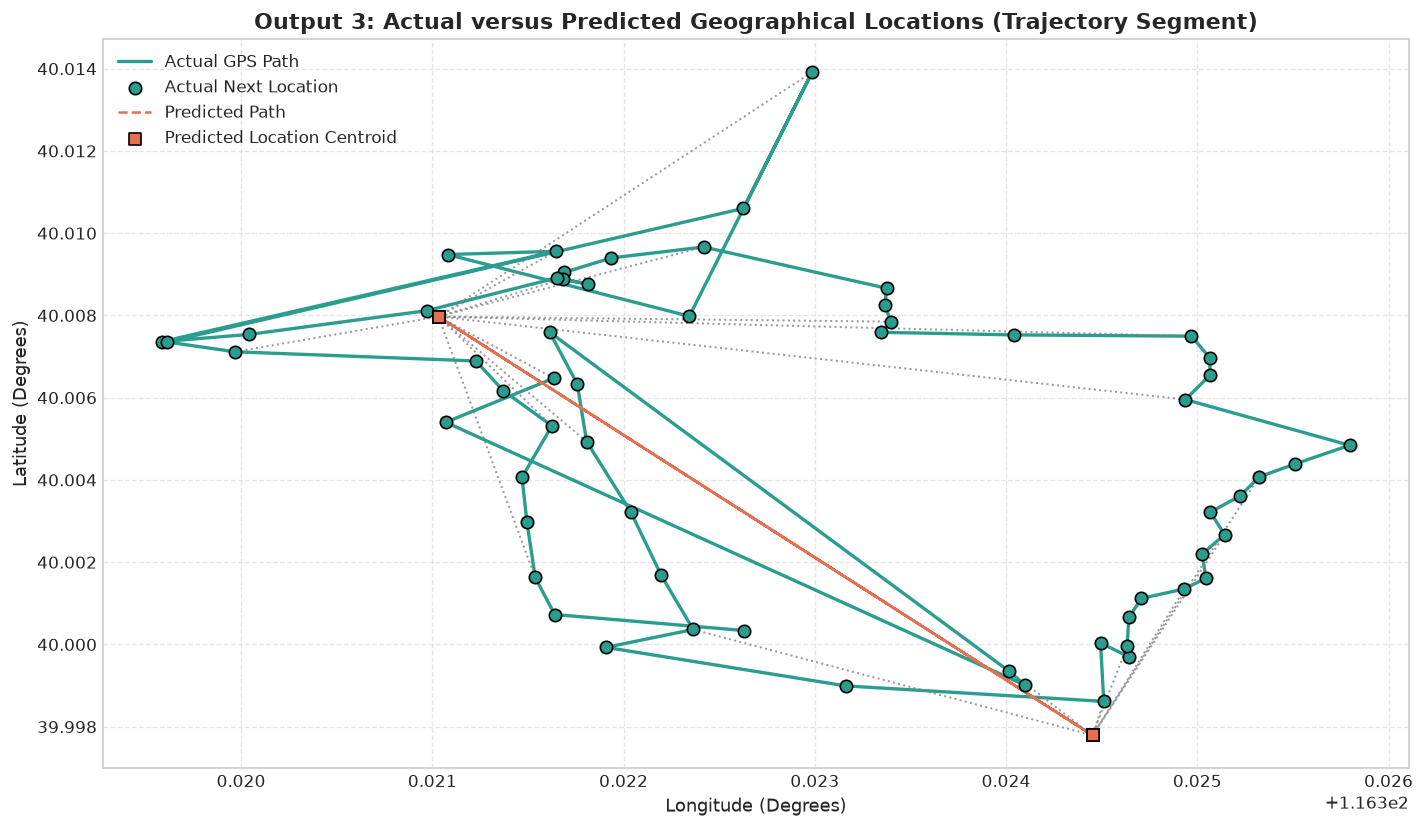

In [ ]:
fig, ax = plt.subplots(figsize=(12, 7))

act = baseline_eval['actual_coords']
pred = baseline_eval['pred_coords']

n_points_plot = min(60, len(act))
step_slice = slice(0, n_points_plot)

ax.plot(act[step_slice, 1], act[step_slice, 0], color='#2a9d8f', linewidth=2, linestyle='-', label='Actual GPS Path', zorder=2)
ax.scatter(act[step_slice, 1], act[step_slice, 0], color='#2a9d8f', edgecolors='k', s=55, label='Actual Next Location', zorder=4)

ax.plot(pred[step_slice, 1], pred[step_slice, 0], color='#e76f51', linewidth=1.5, linestyle='--', label='Predicted Path', zorder=2)
ax.scatter(pred[step_slice, 1], pred[step_slice, 0], color='#e76f51', marker='s', edgecolors='k', s=60, label='Predicted Location Centroid', zorder=4)

for i in range(0, n_points_plot, 3):
    ax.plot([act[i, 1], pred[i, 1]], [act[i, 0], pred[i, 0]], color='gray', linestyle=':', linewidth=1.2, alpha=0.8)

ax.set_title("Output 3: Actual versus Predicted Geographical Locations (Trajectory Segment)", fontsize=13, fontweight='bold')
ax.set_xlabel("Longitude (Degrees)", fontsize=11)
ax.set_ylabel("Latitude (Degrees)", fontsize=11)
ax.legend(loc="upper left")
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


In [ ]:
K_candidates = [5, 10, 15, 20]
exp1_metrics = []

for k in K_candidates:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(train_coords)
    train_k = km.predict(train_coords)
    test_k = km.predict(test_coords)
    centroids_k = km.cluster_centers_
    
    hmm_k = LocationHMM(n_states=3, n_symbols=k, random_state=42).fit(train_k, max_iter=25)
    
    res = evaluate_location_prediction(hmm_k, test_k, test_coords, centroids_k, history_len=5)
    
    exp1_metrics.append({
        "Number of Clusters (K)": k,
        "Top-1 Accuracy": f"{res['Top-1 Accuracy']*100:.2f}%",
        "Top-3 Accuracy": f"{res['Top-3 Accuracy']*100:.2f}%",
        "Mean Haversine (km)": f"{res['Mean Haversine (km)']:.3f}",
        "Median Haversine (km)": f"{res['Median Haversine (km)']:.3f}",
        "F1-Score": f"{res['F1-Score (Macro)']:.4f}",
        "Train Time (s)": f"{hmm_k.train_time:.3f}",
        "top1_raw": res['Top-1 Accuracy'],
        "top3_raw": res['Top-3 Accuracy'],
        "dist_raw": res['Mean Haversine (km)']
    })

df_exp1 = pd.DataFrame(exp1_metrics)
print("Experiment 1: Effect of Cluster Count (K) on Location Prediction:")
display(df_exp1[["Number of Clusters (K)", "Top-1 Accuracy", "Top-3 Accuracy", "Mean Haversine (km)", "Median Haversine (km)", "F1-Score", "Train Time (s)"]])


,Number of Clusters (K),Top-1 Accuracy,Top-3 Accuracy,Mean Haversine (km),Median Haversine (km),F1-Score,Train Time (s)
0,5,90.42%,99.58%,0.731,0.489,0.3166,0.329
1,10,76.67%,93.75%,0.632,0.305,0.3375,0.178
2,15,73.75%,78.33%,0.589,0.250,0.2679,0.194
3,20,63.33%,72.50%,0.644,0.274,0.1651,0.320


Experiment 1: Effect of Cluster Count (K) on Location Prediction:


In [ ]:
fractions = [0.50, 0.60, 0.80]
exp2_metrics = []

for frac in fractions:
    n_pts = int(frac * len(train_clusters))
    sub_train = train_clusters[:n_pts]
    
    hmm_frac = LocationHMM(n_states=3, n_symbols=K_default, random_state=42).fit(sub_train, max_iter=25)
    res_frac = evaluate_location_prediction(hmm_frac, test_clusters, test_coords, cluster_centroids, history_len=5)
    
    exp2_metrics.append({
        "Training Fraction": f"{int(frac*100)}%",
        "Training Points": n_pts,
        "Top-1 Accuracy": f"{res_frac['Top-1 Accuracy']*100:.2f}%",
        "Top-3 Accuracy": f"{res_frac['Top-3 Accuracy']*100:.2f}%",
        "Mean Haversine (km)": f"{res_frac['Mean Haversine (km)']:.3f}",
        "F1-Score": f"{res_frac['F1-Score (Macro)']:.4f}",
        "Train Time (s)": f"{hmm_frac.train_time:.3f}"
    })

df_exp2 = pd.DataFrame(exp2_metrics)
print("Experiment 2: Effect of Training Sequence Length:")
display(df_exp2)


,Training Fraction,Training Points,Top-1 Accuracy,Top-3 Accuracy,Mean Haversine (km),F1-Score,Train Time (s)
0,50%,488,52.92%,89.58%,3.959,0.1416,0.088
1,60%,585,76.67%,89.58%,0.632,0.3375,0.106
2,80%,780,76.67%,90.00%,0.632,0.3375,0.277


Experiment 2: Effect of Training Sequence Length:


In [ ]:
M_candidates = [2, 3, 5, 8]
exp3_metrics = []

for m in M_candidates:
    hmm_m = LocationHMM(n_states=m, n_symbols=K_default, random_state=42).fit(train_clusters, max_iter=25)
    res_m = evaluate_location_prediction(hmm_m, test_clusters, test_coords, cluster_centroids, history_len=5)
    
    exp3_metrics.append({
        "Hidden States (M)": m,
        "Top-1 Accuracy": f"{res_m['Top-1 Accuracy']*100:.2f}%",
        "Top-3 Accuracy": f"{res_m['Top-3 Accuracy']*100:.2f}%",
        "Mean Haversine (km)": f"{res_m['Mean Haversine (km)']:.3f}",
        "F1-Score": f"{res_m['F1-Score (Macro)']:.4f}",
        "Train Time (s)": f"{hmm_m.train_time:.3f}",
        "top1_raw": res_m['Top-1 Accuracy'],
        "top3_raw": res_m['Top-3 Accuracy'],
        "dist_raw": res_m['Mean Haversine (km)']
    })

df_exp3 = pd.DataFrame(exp3_metrics)
print("Experiment 3: Effect of Hidden State Count (M):")
display(df_exp3[["Hidden States (M)", "Top-1 Accuracy", "Top-3 Accuracy", "Mean Haversine (km)", "F1-Score", "Train Time (s)"]])


,Hidden States (M),Top-1 Accuracy,Top-3 Accuracy,Mean Haversine (km),F1-Score,Train Time (s)
0,2,57.50%,97.50%,0.750,0.1546,0.214
1,3,76.67%,93.75%,0.632,0.3375,0.213
2,5,69.17%,96.67%,0.534,0.6170,0.344
3,8,88.75%,98.33%,0.403,0.8649,0.377


Experiment 3: Effect of Hidden State Count (M):


In [ ]:
all_train_coords = np.vstack([user_data[f"{u}_train"][['lat', 'lon']].values for u in selected_users])
global_kmeans = KMeans(n_clusters=K_default, random_state=42, n_init=10).fit(all_train_coords)
global_centroids = global_kmeans.cluster_centers_

user_seqs_train = {}
user_seqs_test = {}

for u in selected_users:
    user_seqs_train[u] = global_kmeans.predict(user_data[f"{u}_train"][['lat', 'lon']].values)
    user_seqs_test[u] = global_kmeans.predict(user_data[f"{u}_test"][['lat', 'lon']].values)

user_specific_models = {}
for u in selected_users:
    user_specific_models[u] = LocationHMM(n_states=3, n_symbols=K_default, random_state=42).fit(user_seqs_train[u], max_iter=25)

shared_sequences = [user_seqs_train[u] for u in selected_users]
shared_hmm = LocationHMM(n_states=3, n_symbols=K_default, random_state=42).fit(shared_sequences, max_iter=25)

exp4_results = []
for u in selected_users:
    test_coords_u = user_data[f"{u}_test"][['lat', 'lon']].values
    
    res_spec = evaluate_location_prediction(user_specific_models[u], user_seqs_test[u], test_coords_u, global_centroids, history_len=5)
    res_shared = evaluate_location_prediction(shared_hmm, user_seqs_test[u], test_coords_u, global_centroids, history_len=5)

    exp4_results.append({
        "User ID": u,
        "Model Type": "User-Specific HMM",
        "Top-1 Accuracy": f"{res_spec['Top-1 Accuracy']*100:.2f}%",
        "Top-3 Accuracy": f"{res_spec['Top-3 Accuracy']*100:.2f}%",
        "Mean Haversine (km)": f"{res_spec['Mean Haversine (km)']:.3f}",
        "F1-Score": f"{res_spec['F1-Score (Macro)']:.4f}"
    })
    exp4_results.append({
        "User ID": u,
        "Model Type": "Shared HMM (Multi-User)",
        "Top-1 Accuracy": f"{res_shared['Top-1 Accuracy']*100:.2f}%",
        "Top-3 Accuracy": f"{res_shared['Top-3 Accuracy']*100:.2f}%",
        "Mean Haversine (km)": f"{res_shared['Mean Haversine (km)']:.3f}",
        "F1-Score": f"{res_shared['F1-Score (Macro)']:.4f}"
    })

df_exp4 = pd.DataFrame(exp4_results)
print("Experiment 4: User-Specific vs Shared HMM Comparison:")
display(df_exp4)


,User ID,Model Type,Top-1 Accuracy,Top-3 Accuracy,Mean Haversine (km),F1-Score
0,000,User-Specific HMM,96.67%,100.00%,1.373,0.9331
1,000,Shared HMM (Multi-User),85.42%,100.00%,1.502,0.4607
2,001,User-Specific HMM,80.38%,99.43%,3.731,0.4937
3,001,Shared HMM (Multi-User),33.99%,99.84%,5.524,0.1472
4,002,User-Specific HMM,90.44%,99.63%,1.338,0.4556
5,002,Shared HMM (Multi-User),90.07%,96.30%,1.350,0.2681


Experiment 4: User-Specific vs Shared HMM Comparison:


In [ ]:
history_lengths = [2, 5, 10, 20]
exp5_hist_results = []

for l_len in history_lengths:
    res_l = evaluate_location_prediction(hmm_baseline, test_clusters, test_coords, cluster_centroids, history_len=l_len)
    exp5_hist_results.append({
        "History Length (L)": l_len,
        "Top-1 Accuracy": f"{res_l['Top-1 Accuracy']*100:.2f}%",
        "Top-3 Accuracy": f"{res_l['Top-3 Accuracy']*100:.2f}%",
        "Mean Haversine (km)": f"{res_l['Mean Haversine (km)']:.3f}"
    })
horizons = [1, 2, 3, 5]
exp5_horizon_results = []
test_len = len(test_clusters)

for h in horizons:
    top1_h, top3_h, haversine_h = 0, 0, []
    count_h = 0
    for t in range(5, test_len - h):
        window = test_clusters[t-5:t]
        actual_target = test_clusters[t + h - 1]
        act_lat, act_lon = test_coords[t + h - 1]
        
        alpha_curr = hmm_baseline.forward_state_distribution(window)
        state_h = alpha_curr
        for _ in range(h):
            state_h = state_h @ hmm_baseline.A
        probs_h = state_h @ hmm_baseline.B
        probs_h /= np.sum(probs_h)
        
        top1_pred = int(np.argmax(probs_h))
        top3_pred = list(np.argsort(probs_h)[-3:][::-1])
        
        p_lat, p_lon = cluster_centroids[top1_pred]
        dist = haversine_distance(act_lat, act_lon, p_lat, p_lon)
        haversine_h.append(dist)
        
        if top1_pred == actual_target:
            top1_h += 1
        if actual_target in top3_pred:
            top3_h += 1
        count_h += 1
        
    exp5_horizon_results.append({
        "Prediction Horizon (h steps)": f"+{h} step(s)",
        "Top-1 Accuracy": f"{top1_h / count_h * 100:.2f}%",
        "Top-3 Accuracy": f"{top3_h / count_h * 100:.2f}%",
        "Mean Haversine (km)": f"{np.mean(haversine_h):.3f}"
    })

print("Experiment 5 (A): Effect of Observed Trajectory Length:")
display(pd.DataFrame(exp5_hist_results))

print("\nExperiment 5 (B): Prediction Decay over Multi-Step Lookahead Horizons:")
display(pd.DataFrame(exp5_horizon_results))


,History Length (L),Top-1 Accuracy,Top-3 Accuracy,Mean Haversine (km)
0,2,76.95%,93.83%,0.625
1,5,76.67%,93.75%,0.632
2,10,77.02%,94.04%,0.633
3,20,76.44%,93.78%,0.647


,Prediction Horizon (h steps),Top-1 Accuracy,Top-3 Accuracy,Mean Haversine (km)
0,+1 step(s),76.57%,93.72%,0.634
1,+2 step(s),68.91%,89.08%,0.689
2,+3 step(s),62.87%,85.23%,0.726
3,+5 step(s),56.60%,94.47%,0.782


Experiment 5 (A): Effect of Observed Trajectory Length:

Experiment 5 (B): Prediction Decay over Multi-Step Lookahead Horizons:


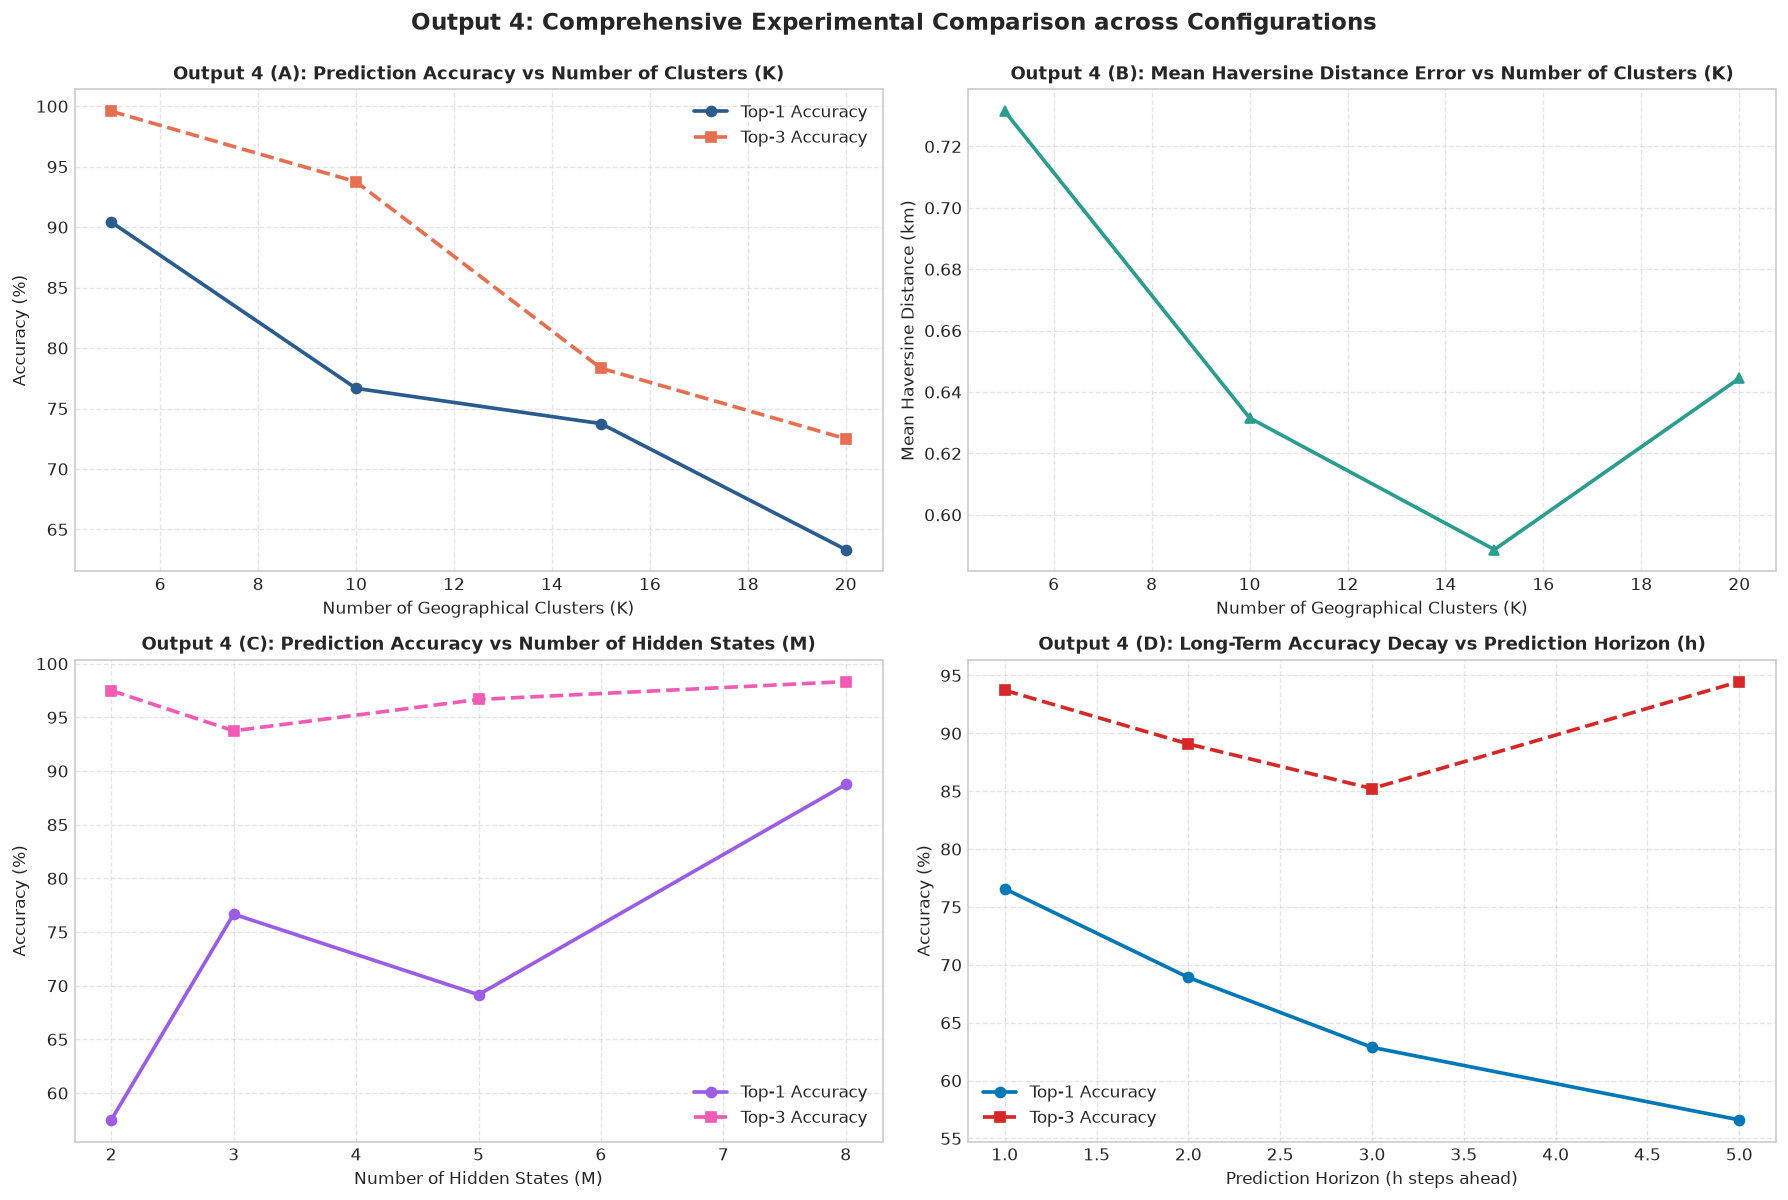

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0, 0].plot(K_candidates, [d['top1_raw']*100 for d in exp1_metrics], marker='o', linewidth=2.2, color='#2b5c8f', label='Top-1 Accuracy')
axes[0, 0].plot(K_candidates, [d['top3_raw']*100 for d in exp1_metrics], marker='s', linewidth=2.2, linestyle='--', color='#e76f51', label='Top-3 Accuracy')
axes[0, 0].set_title("Output 4 (A): Prediction Accuracy vs Number of Clusters (K)", fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel("Number of Geographical Clusters (K)")
axes[0, 0].set_ylabel("Accuracy (%)")
axes[0, 0].legend()
axes[0, 0].grid(True, linestyle="--", alpha=0.5)

axes[0, 1].plot(K_candidates, [d['dist_raw'] for d in exp1_metrics], marker='^', linewidth=2.2, color='#2a9d8f')
axes[0, 1].set_title("Output 4 (B): Mean Haversine Distance Error vs Number of Clusters (K)", fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel("Number of Geographical Clusters (K)")
axes[0, 1].set_ylabel("Mean Haversine Distance (km)")
axes[0, 1].grid(True, linestyle="--", alpha=0.5)

axes[1, 0].plot(M_candidates, [d['top1_raw']*100 for d in exp3_metrics], marker='o', linewidth=2.2, color='#9b5de5', label='Top-1 Accuracy')
axes[1, 0].plot(M_candidates, [d['top3_raw']*100 for d in exp3_metrics], marker='s', linewidth=2.2, linestyle='--', color='#f15bb5', label='Top-3 Accuracy')
axes[1, 0].set_title("Output 4 (C): Prediction Accuracy vs Number of Hidden States (M)", fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel("Number of Hidden States (M)")
axes[1, 0].set_ylabel("Accuracy (%)")
axes[1, 0].legend()
axes[1, 0].grid(True, linestyle="--", alpha=0.5)

h_steps = [1, 2, 3, 5]
h_accs = [float(d['Top-1 Accuracy'].replace('%', '')) for d in exp5_horizon_results]
h_top3 = [float(d['Top-3 Accuracy'].replace('%', '')) for d in exp5_horizon_results]

axes[1, 1].plot(h_steps, h_accs, marker='o', linewidth=2.2, color='#0077b6', label='Top-1 Accuracy')
axes[1, 1].plot(h_steps, h_top3, marker='s', linewidth=2.2, linestyle='--', color='#d62828', label='Top-3 Accuracy')
axes[1, 1].set_title("Output 4 (D): Long-Term Accuracy Decay vs Prediction Horizon (h)", fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel("Prediction Horizon (h steps ahead)")
axes[1, 1].set_ylabel("Accuracy (%)")
axes[1, 1].legend()
axes[1, 1].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Output 4: Comprehensive Experimental Comparison across Configurations", fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()
